Realizado por:
Andrea Bonilla
July Aparicio
Ioshua Castillejos

# Clasificación de Sentimientos de Reseñas de Películas en IMDb con Redes Neuronales Recurrentes
## A - Objetivo

Desarrollar un método basado en redes neuronales recurrentes que permita clasificar con precisión las reseñas de películas en IMDb en una de las dos
categorías: positiva o negativa

## B - Conjunto de datos

Los datos corresponden a un dataset de reseñas de películas en IMDb,
disponibles en el siguiente enlace. El dataset contiene miles de reseñas
etiquetadas con su correspondiente rating y etiqueta de sentimiento (positivo o
negativo)

## C - Actividades por realizar
1. Preprocesamiento de las reseñas: Construir un pipeline que permita limpiar y
tokenizar las reseñas de texto, convirtiéndolas en secuencias numéricas
utilizando embeddings
2. Desarrollo de la arquitectura de red neuronal recurrente: Implementar una
RNN (por ejemplo, LSTM o GRU) para la clasificación de las reseñas en dos
categorías. La arquitectura de la red es de libre elección, pero se sugiere incluir
capas de embedding, capas recurrentes y una capa densa de salida con
activación sigmoide. Justificar la elección de cada capa del modelo.
3. Entrenamiento y evaluación del modelo: Dividir el dataset en conjuntos de
entrenamiento, validación y prueba. Entrenar el modelo utilizando el conjunto de
entrenamiento y evaluar su rendimiento con el conjunto de prueba, reportando
métricas de precisión, recall y F1-score.

### 1. Librerias


In [39]:
#Importamos las librerias requeridas
#Importamos pytorch con los modulos para construir redes neuronales
import pandas as pd               # Librería para manejo de dataframes
import numpy as np                # Librería para trabajar con datos matriciales
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split


import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader, random_split

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score   # Importar métricas de validación
from sklearn.preprocessing import StandardScaler

from time import time
from gensim.models import Word2Vec
from nltk.stem import PorterStemmer
stemmer = PorterStemmer()

import copy

# Usar el almacén de certificados del sistema operativo (evita CERTIFICATE_VERIFY_FAILED
# en redes con proxy corporativo, sobre todo con Python 3.13)
try:
    import truststore
    truststore.inject_into_ssl()
except ImportError:
    pass

import nltk
from nltk.corpus import stopwords
from wordcloud import WordCloud

# Descargar solo los recursos que no estén ya instalados
for recurso, ruta in [('punkt', 'tokenizers/punkt'),
                      ('punkt_tab', 'tokenizers/punkt_tab'),
                      ('stopwords', 'corpora/stopwords')]:
    try:
        nltk.data.find(ruta)
    except LookupError:
        nltk.download(recurso, quiet=True)

#Inicializamos las semillas
torch.manual_seed(42)
np.random.seed(42)

#Se define el uso de GPU y cuda para el procesamiento de las redes convolucionales
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Usando dispositivo: {device}')

Usando dispositivo: cuda


### 2. Importar los datos

In [40]:
GHI = pd.read_csv('movie.csv')
GHI.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    40000 non-null  object
 1   label   40000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 625.1+ KB


### 3. Exploración de datos

In [41]:
GHI.head()

,text,label
0,I grew up (b. 1965) watching and loving the Th...,0
1,"When I put this movie in my DVD player, and sa...",0
2,Why do people who do not know what a particula...,0
3,Even though I have great interest in Biblical ...,0
4,Im a die hard Dads Army fan and nothing will e...,1


In [42]:
GHI['label'].value_counts()

label
0    20019
1    19981
Name: count, dtype: int64

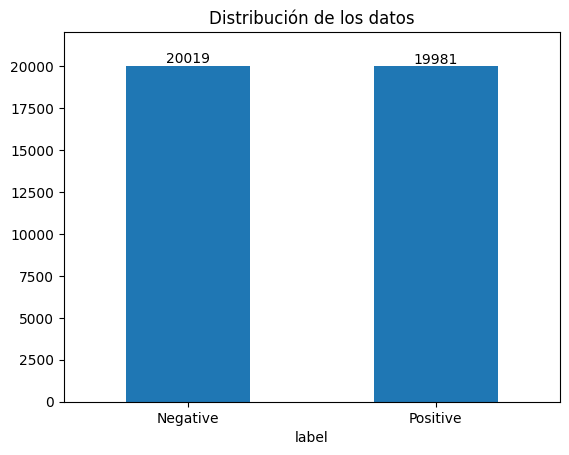

In [43]:
ax = GHI.groupby('label').count().plot(kind='bar', title='Distribución de los datos',
                                       legend=False)
ax.set_xticklabels(['Negative', 'Positive'], rotation=0)

for container in ax.containers:
    ax.bar_label(container)

ax.margins(y=0.1)  # deja espacio arriba para que no se corte el número


In [44]:
longitudes = GHI['text'].str.split().str.len()
print(f"Textos muy cortos (<5 palabras): {(longitudes < 5).sum()}")
print(f"Textos muy largos (>1000 palabras): {(longitudes > 1000).sum()}")
print(f"Filas con registros nulos: {GHI['text'].isnull().sum()}")
print(f"Filas invalidas: {GHI['text'].isna().sum()}")
print(f"Filas duplicadas: {GHI['text'].duplicated().sum()}")

Textos muy cortos (<5 palabras): 1
Textos muy largos (>1000 palabras): 60
Filas con registros nulos: 0
Filas invalidas: 0
Filas duplicadas: 277


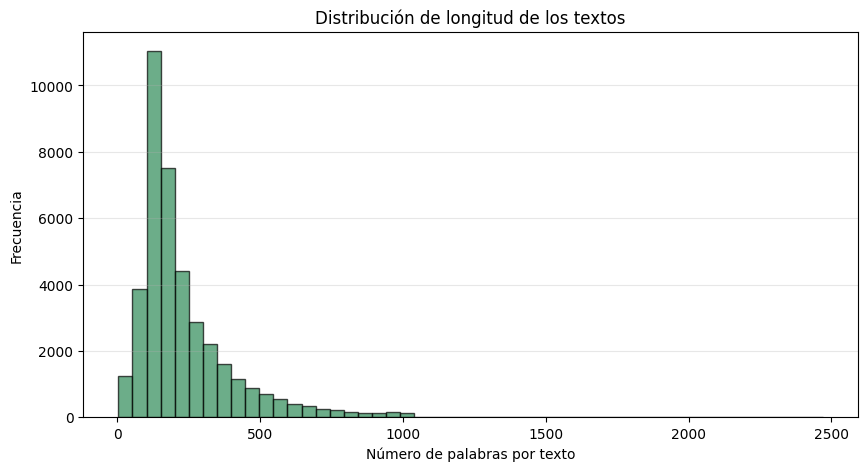

count    40000.000000
mean       231.339250
std        171.194123
min          4.000000
25%        126.000000
50%        173.000000
75%        282.000000
max       2470.000000
Name: text, dtype: float64


In [45]:
longitudes = GHI['text'].str.split().str.len()

plt.figure(figsize=(10,5))
plt.hist(longitudes, bins=50, color='seagreen', edgecolor='black', alpha=0.7)
plt.xlabel('Número de palabras por texto')
plt.ylabel('Frecuencia')
plt.title('Distribución de longitud de los textos')
plt.grid(axis='y', alpha=0.3)
plt.show()

print(longitudes.describe())

Hallazgos de la exploración de datos.

Observamos una distribución normal de los datos muestra que el total de reseñas esta distribuido para cada etiqueta (Positiva y Negativa). Se detectaron 277 registros duplicados, por lo que se hara una limpieza de estos. Se observa que la media de los textos esta en 231 palabras, y en los extremos de nuestro rango tenemos textos desde 4 palabras hasta 2470 palabras.

### 4. Separación de datos

In [46]:
# Quitar duplicados antes de dividir, para que una reseña no quede en entrenamiento y prueba a la vez
GHI = GHI.drop_duplicates(subset='text').reset_index(drop=True)
print(f"Registros tras eliminar duplicados: {len(GHI)}")

SEED = 42

# 70% train, 15% validación, 15% prueba
train_GHI, resto = train_test_split(GHI, test_size=0.30, stratify=GHI["label"], random_state=SEED)
val_GHI, test_GHI = train_test_split(resto, test_size=0.50, stratify=resto["label"], random_state=SEED)
print(f"Datos entrenamiento: {len(train_GHI)}\nDatos validacion: {len(val_GHI)} \nDatos prueba: {len(test_GHI)}")

Registros tras eliminar duplicados: 39723
Datos entrenamiento: 27806
Datos validacion: 5958 
Datos prueba: 5959


### 5. Función de limpieza de textos

In [47]:
import re
import html

# Stopwords de NLTK, pero conservando negaciones e intensificadores (cambian el sentimiento)
conservar = {'no', 'nor', 'not', 'but', 'very', 'too', 'against', 'only'}
stop_words = set(stopwords.words('english')) - conservar

def limpiar_texto(texto, quitar_stopwords=True):
    texto = html.unescape(texto)                       # &amp; -> &
    texto = re.sub(r'<[^>]+>', ' ', texto)             # etiquetas HTML (<br />)
    texto = re.sub(r'http\S+|www\.\S+', ' ', texto)    # URLs
    texto = texto.lower().replace('\u2019', "'")       # minúsculas y apóstrofo tipográfico
    texto = re.sub(r"\bwon't\b", 'will not', texto)    # negaciones irregulares
    texto = re.sub(r"\bcan't\b", 'can not', texto)
    texto = re.sub(r"n't\b", ' not', texto)            # didn't -> did not
    texto = re.sub(r"'(s|re|ve|d|ll|m)\b", ' ', texto) # otras contracciones
    texto = re.sub(r'[^a-z\s]', ' ', texto)            # solo letras
    palabras_limpias = texto.split()
    if quitar_stopwords:
        palabras_limpias = [t for t in palabras_limpias if t not in stop_words and len(t) > 1]
        #palabras_limpias = [stemmer.stem(t) for t in palabras_limpias]
    #Regresa una cadena de textos separados en palabras_limpias.
    return palabras_limpias

print(limpiar_texto("I didn't like it.<br /><br />It WASN'T good &amp; I can't recommend it!!"))
# ['not', 'like', 'not', 'good', 'not', 'recommend']

# Se aplica la misma limpieza a cada conjunto (es por reseña, así que no hay fuga de información)
for conjunto in (train_GHI, val_GHI, test_GHI):
    conjunto['palabras_limpias'] = conjunto['text'].apply(limpiar_texto)

['not', 'like', 'not', 'good', 'not', 'recommend']


### 6. Vocabulario y tensores (compartido)

In [48]:
from collections import Counter

MAX_VOCAB = 20000
MAX_LEN = 300

# Vocabulario construido solo con train (evita fuga de información). 0 = <PAD>, 1 = <UNK>
contador = Counter(t for toks in train_GHI["palabras_limpias"] for t in toks)
palabras = [p for p, _ in contador.most_common(MAX_VOCAB - 2)]
word2idx = {p: i + 2 for i, p in enumerate(palabras)}
VOCAB_SIZE = len(word2idx) + 2

def codificar(tokens):
    ids = [word2idx.get(t, 1) for t in tokens][:MAX_LEN]
    # padding al inicio para que el último paso de la LSTM sea una palabra real
    return [0] * (MAX_LEN - len(ids)) + ids

### 7. Definición del modelo (base)

El modelo empieza con una capa de embedding que se inicializa con los vectores de Word2Vec entrenados con las reseñas de entrenamiento. Se hizo así para que la red no arranque desde cero y ya tenga una idea de qué palabras se parecen entre sí, por ejemplo *great* y *excellent*. Esta capa se dejó entrenable para que los vectores se puedan ajustar a la clasificación de sentimiento. El índice 0 se usa para el padding y queda en ceros.

Después del embedding se agregó un dropout de 0.3, porque con un vocabulario de 20.000 palabras el modelo puede aprenderse palabras específicas de memoria y no generalizar bien.

La parte principal es una LSTM bidireccional de 128 unidades. Se escogió LSTM en lugar de una RNN simple porque las reseñas son largas (se cortaron en 300 palabras) y la RNN simple tiende a olvidar lo que leyó al principio por el desvanecimiento del gradiente. Se usó bidireccional porque el sentido de una palabra a veces depende de lo que viene después, como en "not bad at all". Los estados finales de las dos direcciones se concatenan y quedan en un vector de 256.

A la salida de la LSTM se puso otro dropout, esta vez de 0.4, y luego una capa densa de 64 neuronas con ReLU que combina la información antes de clasificar.

La última capa tiene una sola neurona y da la probabilidad de que la reseña sea positiva; si es 0.5 o más se toma como positiva. La sigmoide no va dentro del modelo sino en la función de pérdida, `BCEWithLogitsLoss`, porque así el cálculo es más estable. Al momento de predecir se aplica con `torch.sigmoid`.

Para entrenar se usó Adam con tasa de aprendizaje de 0.001 y se limitó el gradiente a 1.0, ya que en las LSTM los gradientes a veces se disparan y el entrenamiento se vuelve inestable.


In [49]:
class SentimentLSTM(nn.Module):
    def __init__(self, vocab_size, emb_dim=100, hidden_dim=128, num_layers=2, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.emb_dropout = nn.Dropout(dropout)
        self.lstm = nn.LSTM(emb_dim, hidden_dim, num_layers=num_layers,
                            batch_first=True, dropout=dropout if num_layers > 1 else 0)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        emb = self.emb_dropout(self.embedding(x))   # (batch, MAX_LEN, emb_dim)
        _, (h_n, _) = self.lstm(emb)                # h_n: (num_layers, batch, hidden_dim)
        h = self.dropout(h_n[-1])                   # último estado oculto de la última capa
        return self.sigmoid(self.fc(h)).squeeze(1)  # probabilidad de clase positiva

### 8. Modelo Word2Vec

#### A) Embeddings Word2Vec

In [50]:
from gensim.models import Word2Vec

EMB_DIM = 100

w2v = Word2Vec(
    sentences=train_GHI["palabras_limpias"].tolist(),
    vector_size=EMB_DIM,
    window=5,
    min_count=1,
    workers=4,
    seed=42,
)

print(f"Palabras en el modelo Word2Vec: {len(w2v.wv):,}")
print("Similares a 'great':", w2v.wv.most_similar('great', topn=5))

Palabras en el modelo Word2Vec: 78,514
Similares a 'great': [('wonderful', 0.7992849946022034), ('excellent', 0.7873533964157104), ('fine', 0.7760693430900574), ('fantastic', 0.7607752084732056), ('amazing', 0.708509087562561)]


#### B) Matriz con embeddings Word2Vec

In [51]:
# Matriz de embeddings inicializada con los vectores de Word2Vec, alineada con word2idx
matriz_emb = np.random.normal(0, 0.1, (VOCAB_SIZE, EMB_DIM)).astype("float32")
matriz_emb[0] = 0.0   # <PAD> en ceros
encontradas = 0
for palabra, idx in word2idx.items():
    if palabra in w2v.wv:
        matriz_emb[idx] = w2v.wv[palabra]
        encontradas += 1
print(f"Palabras con vector Word2Vec: {encontradas:,} / {len(word2idx):,}")


Palabras con vector Word2Vec: 19,998 / 19,998


#### C) Tensores Word2Vec

In [52]:
#Creación de los tensores, para X asignamos la columna palabras_limpias
#Para el tensor y, asignamos las etiquetas 0 y 1 
def a_tensores(frame):
    X = torch.tensor([codificar(t) for t in frame["palabras_limpias"]], dtype=torch.long)
    y = torch.tensor(frame["label"].values, dtype=torch.float32)
    return X, y

X_train, y_train = a_tensores(train_GHI)
X_val, y_val = a_tensores(val_GHI)
X_test, y_test = a_tensores(test_GHI)

train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=128, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=256)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=256)
print(X_train.shape, X_val.shape, X_test.shape)

torch.Size([27806, 300]) torch.Size([5958, 300]) torch.Size([5959, 300])


#### D) Entrenamiento Word2Vec

In [53]:
modelo = SentimentLSTM(VOCAB_SIZE, EMB_DIM).to(device)
modelo.embedding.weight.data.copy_(torch.tensor(matriz_emb))
modelo.embedding.weight.requires_grad = True
criterio = nn.BCELoss()
optimizador = optim.Adam(modelo.parameters(), lr=1e-3, weight_decay=1e-5)   # weight_decay: regularización L2
# Si la pérdida de validación no mejora en 1 época, la tasa de aprendizaje se reduce a la mitad
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizador, mode="min", factor=0.5, patience=1)

print(modelo)
print(f"Parámetros entrenables: {sum(p.numel() for p in modelo.parameters() if p.requires_grad):,}")

SentimentLSTM(
  (embedding): Embedding(20000, 100, padding_idx=0)
  (emb_dropout): Dropout(p=0.3, inplace=False)
  (lstm): LSTM(100, 128, num_layers=2, batch_first=True, dropout=0.3)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)
Parámetros entrenables: 2,249,985


In [54]:
def ejecutar_epoca(loader, entrenar):
    """Recorre un loader una vez. Si entrenar=True actualiza los pesos. Devuelve (pérdida, accuracy)."""
    modelo.train() if entrenar else modelo.eval()
    perdida_total, aciertos, n = 0.0, 0, 0
    with torch.set_grad_enabled(entrenar):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            prob = modelo(xb)
            perdida = criterio(prob, yb)
            if entrenar:
                optimizador.zero_grad()
                perdida.backward()
                nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
                optimizador.step()
            perdida_total += perdida.item() * len(yb)
            aciertos += ((prob >= 0.5).float() == yb).sum().item()
            n += len(yb)
    return perdida_total / n, aciertos / n

EPOCAS = 50      # máximo de épocas; el early stopping corta antes si ya no mejora
PACIENCIA = 10    # épocas sin mejorar en validación antes de detener el entrenamiento

historial = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
mejor_val_loss = float("inf")
mejor_estado = None
sin_mejora = 0
inicio = time()

for epoca in range(1, EPOCAS + 1):
    tr_loss, tr_acc = ejecutar_epoca(train_loader, entrenar=True)
    va_loss, va_acc = ejecutar_epoca(val_loader, entrenar=False)
    scheduler.step(va_loss)   # ajusta la tasa de aprendizaje según la pérdida de validación
    for k, v in zip(historial, (tr_loss, va_loss, tr_acc, va_acc)):
        historial[k].append(v)
    print(f"Época {epoca:2d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.4f} | lr {optimizador.param_groups[0]['lr']:.1e}")

    if va_loss < mejor_val_loss:
        mejor_val_loss = va_loss
        mejor_estado = copy.deepcopy(modelo.state_dict())
        sin_mejora = 0
    else:
        sin_mejora += 1
        if sin_mejora >= PACIENCIA:
            print(f"Early stopping: la pérdida de validación no mejora hace {PACIENCIA} épocas")
            break

modelo.load_state_dict(mejor_estado)   # se queda con el mejor modelo según validación
print(f"Tiempo de entrenamiento: {time() - inicio:.1f} s | mejor val loss: {mejor_val_loss:.4f}")

Época  1 | train loss 0.4826 acc 0.7727 | val loss 0.3788 acc 0.8409 | lr 1.0e-03
Época  2 | train loss 0.3627 acc 0.8479 | val loss 0.3037 acc 0.8795 | lr 1.0e-03
Época  3 | train loss 0.2929 acc 0.8836 | val loss 0.3145 acc 0.8666 | lr 1.0e-03
Época  4 | train loss 0.2409 acc 0.9052 | val loss 0.2588 acc 0.8973 | lr 1.0e-03
Época  5 | train loss 0.1895 acc 0.9287 | val loss 0.2570 acc 0.8956 | lr 1.0e-03
Época  6 | train loss 0.1468 acc 0.9468 | val loss 0.3070 acc 0.9001 | lr 1.0e-03
Época  7 | train loss 0.1101 acc 0.9618 | val loss 0.3380 acc 0.8847 | lr 5.0e-04
Época  8 | train loss 0.0759 acc 0.9755 | val loss 0.3386 acc 0.8938 | lr 5.0e-04
Época  9 | train loss 0.0578 acc 0.9816 | val loss 0.3987 acc 0.8936 | lr 2.5e-04
Época 10 | train loss 0.0413 acc 0.9869 | val loss 0.4801 acc 0.8857 | lr 2.5e-04
Época 11 | train loss 0.0373 acc 0.9887 | val loss 0.4739 acc 0.8882 | lr 1.3e-04
Época 12 | train loss 0.0312 acc 0.9908 | val loss 0.4748 acc 0.8887 | lr 1.3e-04
Época 13 | train

### 9. Modelo GloVe

#### A) Embeddings Glove

En cada época el modelo se entrena con `train_loader` y se evalúa con `val_loader`. Se guarda el modelo con **menor pérdida de validación** y se detiene el entrenamiento si esta no mejora durante 5 épocas seguidas (*early stopping*), con un máximo de 50 épocas. Además, cuando la pérdida de validación deja de mejorar, la tasa de aprendizaje se reduce a la mitad (`ReduceLROnPlateau`). El conjunto de prueba no se usa en esta etapa.

In [55]:
import os
from gensim.models import KeyedVectors
import gensim.downloader as api

EMB_DIM_GLOVE = 300

if os.path.exists("glove.6B.300d.txt"):
    glove = KeyedVectors.load_word2vec_format("glove.6B.300d.txt", binary=False, no_header=True)
else:
    glove = api.load("glove-wiki-gigaword-300")

print(glove.most_similar("great", topn=5))
print(glove.most_similar("terrible", topn=5))

encontradas_glove = [p for p in word2idx if p in glove]
desv = np.std([glove[p] for p in encontradas_glove])
rng = np.random.default_rng(SEED)

emb_matrix_glove = rng.normal(scale=desv, size=(MAX_VOCAB, EMB_DIM_GLOVE)).astype(np.float32)
emb_matrix_glove[0] = 0
for palabra in encontradas_glove:
    emb_matrix_glove[word2idx[palabra]] = glove[palabra]
print(f"Palabras con vector de GloVe: {len(encontradas_glove):,} de {len(word2idx):,}")

del glove

[('greatest', 0.6583032608032227), ('good', 0.6410046815872192), ('tremendous', 0.6299972534179688), ('well', 0.5856286883354187), ('especially', 0.5592252612113953)]
[('horrible', 0.8621524572372437), ('awful', 0.7882837653160095), ('dreadful', 0.7239290475845337), ('horrendous', 0.6983873844146729), ('horrific', 0.6624177098274231)]
Palabras con vector de GloVe: 19,890 de 19,998


#### B) Tensores Glove

Las secuencias son de 300 palabras, igual que con Word2Vec, con ceros al inicio en las cortas y dejando el comienzo en las largas. Los lotes son de 128 en entrenamiento y de 256 en validación y prueba.

In [56]:
MAX_LEN_GLOVE = 300

def codificar_glove(tokens):
    ids = [word2idx.get(t, 1) for t in tokens][:MAX_LEN_GLOVE]   # se deja el inicio de la reseña
    return [0] * (MAX_LEN_GLOVE - len(ids)) + ids

def a_tensores_glove(df):
    X = torch.tensor([codificar_glove(t) for t in df["palabras_limpias"]], dtype=torch.long)
    y = torch.tensor(df["label"].values, dtype=torch.float32)
    return X, y

X_train_glove, y_train_glove = a_tensores_glove(train_GHI)
X_val_glove, y_val_glove = a_tensores_glove(val_GHI)
X_test_glove, y_test_glove = a_tensores_glove(test_GHI)

train_loader_glove = DataLoader(TensorDataset(X_train_glove, y_train_glove), batch_size=128, shuffle=True)
val_loader_glove = DataLoader(TensorDataset(X_val_glove, y_val_glove), batch_size=256)
test_loader_glove = DataLoader(TensorDataset(X_test_glove, y_test_glove), batch_size=256)
print(X_train_glove.shape, X_val_glove.shape, X_test_glove.shape)

torch.Size([27806, 300]) torch.Size([5958, 300]) torch.Size([5959, 300])


Se usa la misma clase `SentimentLSTM` del modelo con Word2Vec. Solo cambia el embedding, que en este caso es de 300 dimensiones y se inicializa con la matriz de GloVe. El resto se mantiene: dropout de 0.3, dos capas LSTM de 128 unidades, atención y la neurona de salida con sigmoide. El entrenamiento también es igual, con `BCELoss`, Adam (lr = 0.001, weight decay = 1e-5), `ReduceLROnPlateau` y recorte del gradiente a 1.0.

In [57]:
# misma clase SentimentLSTM del modelo con Word2Vec
torch.manual_seed(SEED)
modelo_glove = SentimentLSTM(emb_matrix_glove.shape[0], EMB_DIM_GLOVE).to(device)
modelo_glove.embedding.weight.data.copy_(torch.tensor(emb_matrix_glove))
modelo_glove.embedding.weight.requires_grad = True
criterio_glove = nn.BCELoss()
optimizador_glove = optim.Adam(modelo_glove.parameters(), lr=1e-3, weight_decay=1e-5)  # regularización L2
# Se reduce el lr a la mitad si la pérdida de validación no baja
scheduler_glove = optim.lr_scheduler.ReduceLROnPlateau(optimizador_glove, mode="min", factor=0.5, patience=1)

print(modelo_glove)
print(f"Parámetros entrenables: {sum(p.numel() for p in modelo_glove.parameters() if p.requires_grad):,}")

SentimentLSTM(
  (embedding): Embedding(20000, 300, padding_idx=0)
  (emb_dropout): Dropout(p=0.3, inplace=False)
  (lstm): LSTM(300, 128, num_layers=2, batch_first=True, dropout=0.3)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)
Parámetros entrenables: 6,352,385


#### C) Entrenamiento Glove

In [58]:
def ejecutar_epoca_glove(loader, entrenar):
    modelo_glove.train() if entrenar else modelo_glove.eval()
    perdida_total, aciertos, n = 0.0, 0, 0
    with torch.set_grad_enabled(entrenar):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            prob = modelo_glove(xb)
            perdida = criterio_glove(prob, yb)
            if entrenar:
                optimizador_glove.zero_grad()
                perdida.backward()
                nn.utils.clip_grad_norm_(modelo_glove.parameters(), 1.0)
                optimizador_glove.step()
            perdida_total += perdida.item() * len(yb)
            aciertos += ((prob >= 0.5).float() == yb).sum().item()
            n += len(yb)
    return perdida_total / n, aciertos / n

EPOCAS_GLOVE = 50
PACIENCIA_GLOVE = 10

historial_glove = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
mejor_val_loss_glove = float("inf")
mejor_estado_glove = None
sin_mejora = 0
inicio = time()

for epoca in range(1, EPOCAS_GLOVE + 1):
    tr_loss, tr_acc = ejecutar_epoca_glove(train_loader_glove, entrenar=True)
    va_loss, va_acc = ejecutar_epoca_glove(val_loader_glove, entrenar=False)
    scheduler_glove.step(va_loss)
    for k, v in zip(historial_glove, (tr_loss, va_loss, tr_acc, va_acc)):
        historial_glove[k].append(v)
    print(f"Época {epoca:2d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.4f} | lr {optimizador_glove.param_groups[0]['lr']:.1e}")

    if va_loss < mejor_val_loss_glove:
        mejor_val_loss_glove = va_loss
        mejor_estado_glove = copy.deepcopy(modelo_glove.state_dict())
        sin_mejora = 0
    else:
        sin_mejora += 1
        if sin_mejora >= PACIENCIA_GLOVE:
            print(f"Early stopping: la pérdida de validación no mejora hace {PACIENCIA_GLOVE} épocas")
            break

modelo_glove.load_state_dict(mejor_estado_glove)  # mejor modelo
print(f"Tiempo de entrenamiento: {time() - inicio:.1f} s | mejor val loss: {mejor_val_loss_glove:.4f}")

Época  1 | train loss 0.4676 acc 0.7859 | val loss 0.3333 acc 0.8651 | lr 1.0e-03
Época  2 | train loss 0.2960 acc 0.8841 | val loss 0.2938 acc 0.8865 | lr 1.0e-03
Época  3 | train loss 0.2282 acc 0.9157 | val loss 0.2892 acc 0.8847 | lr 1.0e-03
Época  4 | train loss 0.1812 acc 0.9347 | val loss 0.3158 acc 0.8902 | lr 1.0e-03
Época  5 | train loss 0.1302 acc 0.9559 | val loss 0.3205 acc 0.8834 | lr 5.0e-04
Época  6 | train loss 0.0831 acc 0.9745 | val loss 0.3743 acc 0.8827 | lr 5.0e-04
Época  7 | train loss 0.0587 acc 0.9831 | val loss 0.4262 acc 0.8810 | lr 2.5e-04
Época  8 | train loss 0.0437 acc 0.9888 | val loss 0.4666 acc 0.8770 | lr 2.5e-04
Época  9 | train loss 0.0353 acc 0.9911 | val loss 0.5087 acc 0.8795 | lr 1.3e-04
Época 10 | train loss 0.0314 acc 0.9921 | val loss 0.5236 acc 0.8776 | lr 1.3e-04
Época 11 | train loss 0.0273 acc 0.9936 | val loss 0.5273 acc 0.8763 | lr 6.3e-05
Época 12 | train loss 0.0239 acc 0.9946 | val loss 0.5358 acc 0.8781 | lr 6.3e-05
Época 13 | train

### 10. Comparación Word2Vec vs GloVe

In [59]:
mejor_w2v   = max(historial["val_acc"])
mejor_glove = max(historial_glove["val_acc"])
print(f"Word2Vec → mejor val_acc = {mejor_w2v:.4f}")
print(f"GloVe    → mejor val_acc = {mejor_glove:.4f}")
print("Ganador:", "Word2Vec" if mejor_w2v > mejor_glove else "GloVe")

Word2Vec → mejor val_acc = 0.9001
GloVe    → mejor val_acc = 0.8902
Ganador: Word2Vec


### 11. Word2Vec Semilla 3

In [62]:
# ===== Word2Vec - Semilla 3 =====
SEMILLA = 3                          # <<< ÚNICO número a cambiar (3 -> 5)
torch.manual_seed(SEMILLA)
np.random.seed(SEMILLA)

# 1) Re-entrenar Word2Vec con la nueva semilla
w2v_s3 = Word2Vec(
    sentences=train_GHI["palabras_limpias"].tolist(),
    vector_size=EMB_DIM, window=5, min_count=1, workers=4, seed=SEMILLA,
)

# 2) Matriz de embeddings alineada con word2idx
matriz_emb_s3 = np.random.normal(0, 0.1, (VOCAB_SIZE, EMB_DIM)).astype("float32")
matriz_emb_s3[0] = 0.0
for palabra, idx in word2idx.items():
    if palabra in w2v_s3.wv:
        matriz_emb_s3[idx] = w2v_s3.wv[palabra]

# 3) Modelo (reutiliza la clase SentimentLSTM)
modelo_s3 = SentimentLSTM(VOCAB_SIZE, EMB_DIM).to(device)
modelo_s3.embedding.weight.data.copy_(torch.tensor(matriz_emb_s3))
modelo_s3.embedding.weight.requires_grad = True
criterio_s3 = nn.BCELoss()
optimizador_s3 = optim.Adam(modelo_s3.parameters(), lr=1e-3, weight_decay=1e-5)
scheduler_s3 = optim.lr_scheduler.ReduceLROnPlateau(optimizador_s3, mode="min", factor=0.5, patience=1)

# 4) Función de época
def ejecutar_epoca_s3(loader, entrenar):
    modelo_s3.train() if entrenar else modelo_s3.eval()
    perdida_total, aciertos, n = 0.0, 0, 0
    with torch.set_grad_enabled(entrenar):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            prob = modelo_s3(xb)
            perdida = criterio_s3(prob, yb)
            if entrenar:
                optimizador_s3.zero_grad()
                perdida.backward()
                nn.utils.clip_grad_norm_(modelo_s3.parameters(), 1.0)
                optimizador_s3.step()
            perdida_total += perdida.item() * len(yb)
            aciertos += ((prob >= 0.5).float() == yb).sum().item()
            n += len(yb)
    return perdida_total / n, aciertos / n

# 5) Entrenamiento con validación y early stopping
EPOCAS = 50
PACIENCIA = 10
historial_s3 = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
mejor_val_loss_s3 = float("inf")
mejor_estado_s3 = None
sin_mejora = 0
inicio = time()

for epoca in range(1, EPOCAS + 1):
    tr_loss, tr_acc = ejecutar_epoca_s3(train_loader, entrenar=True)
    va_loss, va_acc = ejecutar_epoca_s3(val_loader, entrenar=False)
    scheduler_s3.step(va_loss)
    for k, v in zip(historial_s3, (tr_loss, va_loss, tr_acc, va_acc)):
        historial_s3[k].append(v)
    print(f"Epoca {epoca:2d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.4f} | lr {optimizador_s3.param_groups[0]['lr']:.1e}")

    if va_loss < mejor_val_loss_s3:
        mejor_val_loss_s3 = va_loss
        mejor_estado_s3 = copy.deepcopy(modelo_s3.state_dict())
        sin_mejora = 0
    else:
        sin_mejora += 1
        if sin_mejora >= PACIENCIA:
            print(f"Early stopping: val loss sin mejorar en {PACIENCIA} epocas")
            break

modelo_s3.load_state_dict(mejor_estado_s3)
print(f"Tiempo: {time() - inicio:.1f} s | mejor val loss: {mejor_val_loss_s3:.4f} "
      f"| mejor val acc: {max(historial_s3['val_acc']):.4f}")


Epoca  1 | train loss 0.4689 acc 0.7839 | val loss 0.6182 acc 0.7860 | lr 1.0e-03
Epoca  2 | train loss 0.3441 acc 0.8555 | val loss 0.3211 acc 0.8723 | lr 1.0e-03
Epoca  3 | train loss 0.2936 acc 0.8823 | val loss 0.2793 acc 0.8860 | lr 1.0e-03
Epoca  4 | train loss 0.2414 acc 0.9066 | val loss 0.3032 acc 0.8790 | lr 1.0e-03
Epoca  5 | train loss 0.1952 acc 0.9255 | val loss 0.2755 acc 0.8990 | lr 1.0e-03
Epoca  6 | train loss 0.1483 acc 0.9469 | val loss 0.2815 acc 0.9035 | lr 1.0e-03
Epoca  7 | train loss 0.1168 acc 0.9599 | val loss 0.3141 acc 0.8949 | lr 5.0e-04
Epoca  8 | train loss 0.0779 acc 0.9757 | val loss 0.3790 acc 0.8964 | lr 5.0e-04
Epoca  9 | train loss 0.0625 acc 0.9801 | val loss 0.3782 acc 0.8944 | lr 2.5e-04
Epoca 10 | train loss 0.0505 acc 0.9852 | val loss 0.4240 acc 0.8916 | lr 2.5e-04
Epoca 11 | train loss 0.0467 acc 0.9862 | val loss 0.4430 acc 0.8911 | lr 1.3e-04
Epoca 12 | train loss 0.0379 acc 0.9898 | val loss 0.4345 acc 0.8919 | lr 1.3e-04
Epoca 13 | train

### 12. Word2Vec Semilla 5

In [70]:
SEMILLA = 5
torch.manual_seed(SEMILLA)
np.random.seed(SEMILLA)

# 1) Re-entrenar Word2Vec con la nueva semilla
w2v_s5 = Word2Vec(
    sentences=train_GHI["palabras_limpias"].tolist(),
    vector_size=EMB_DIM, window=5, min_count=1, workers=4, seed=SEMILLA,
)

# 2) Matriz de embeddings alineada con word2idx
matriz_emb_s5 = np.random.normal(0, 0.1, (VOCAB_SIZE, EMB_DIM)).astype("float32")
matriz_emb_s5[0] = 0.0
for palabra, idx in word2idx.items():
    if palabra in w2v_s5.wv:
        matriz_emb_s5[idx] = w2v_s5.wv[palabra]

# 3) Modelo (reutiliza la clase SentimentLSTM)
modelo_s5 = SentimentLSTM(VOCAB_SIZE, EMB_DIM).to(device)
modelo_s5.embedding.weight.data.copy_(torch.tensor(matriz_emb_s5))
modelo_s5.embedding.weight.requires_grad = True
criterio_s5 = nn.BCELoss()
optimizador_s5 = optim.Adam(modelo_s5.parameters(), lr=1e-3, weight_decay=1e-5)
scheduler_s5 = optim.lr_scheduler.ReduceLROnPlateau(optimizador_s5, mode="min", factor=0.5, patience=1)

# 4) Función de época
def ejecutar_epoca_s5(loader, entrenar):
    modelo_s5.train() if entrenar else modelo_s5.eval()
    perdida_total, aciertos, n = 0.0, 0, 0
    with torch.set_grad_enabled(entrenar):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            prob = modelo_s5(xb)
            perdida = criterio_s5(prob, yb)
            if entrenar:
                optimizador_s5.zero_grad()
                perdida.backward()
                nn.utils.clip_grad_norm_(modelo_s5.parameters(), 1.0)
                optimizador_s5.step()
            perdida_total += perdida.item() * len(yb)
            aciertos += ((prob >= 0.5).float() == yb).sum().item()
            n += len(yb)
    return perdida_total / n, aciertos / n

# 5) Entrenamiento con validación y early stopping
EPOCAS = 50
PACIENCIA = 10
historial_s5 = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
mejor_val_loss_s5 = float("inf")
mejor_estado_s5 = None
sin_mejora = 0
inicio = time()

for epoca in range(1, EPOCAS + 1):
    tr_loss, tr_acc = ejecutar_epoca_s5(train_loader, entrenar=True)
    va_loss, va_acc = ejecutar_epoca_s5(val_loader, entrenar=False)
    scheduler_s5.step(va_loss)
    for k, v in zip(historial_s5, (tr_loss, va_loss, tr_acc, va_acc)):
        historial_s5[k].append(v)
    print(f"Epoca {epoca:2d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.4f} | lr {optimizador_s5.param_groups[0]['lr']:.1e}")

    if va_loss < mejor_val_loss_s5:
        mejor_val_loss_s5 = va_loss
        mejor_estado_s5 = copy.deepcopy(modelo_s5.state_dict())
        sin_mejora = 0
    else:
        sin_mejora += 1
        if sin_mejora >= PACIENCIA:
            print(f"Early stopping: val loss sin mejorar en {PACIENCIA} epocas")
            break

modelo_s5.load_state_dict(mejor_estado_s5)
print(f"Tiempo: {time() - inicio:.1f} s | mejor val loss: {mejor_val_loss_s5:.4f} "
      f"| mejor val acc: {max(historial_s5['val_acc']):.4f}")


Epoca  1 | train loss 0.4907 acc 0.7711 | val loss 0.5249 acc 0.7920 | lr 1.0e-03
Epoca  2 | train loss 0.3666 acc 0.8481 | val loss 0.3267 acc 0.8718 | lr 1.0e-03
Epoca  3 | train loss 0.2972 acc 0.8818 | val loss 0.2752 acc 0.8899 | lr 1.0e-03
Epoca  4 | train loss 0.2448 acc 0.9046 | val loss 0.2941 acc 0.8951 | lr 1.0e-03
Epoca  5 | train loss 0.1968 acc 0.9261 | val loss 0.3288 acc 0.8864 | lr 5.0e-04
Epoca  6 | train loss 0.1377 acc 0.9504 | val loss 0.3282 acc 0.9000 | lr 5.0e-04
Epoca  7 | train loss 0.1100 acc 0.9616 | val loss 0.3584 acc 0.8914 | lr 2.5e-04
Epoca  8 | train loss 0.0868 acc 0.9705 | val loss 0.3548 acc 0.8961 | lr 2.5e-04
Epoca  9 | train loss 0.0740 acc 0.9758 | val loss 0.3803 acc 0.8916 | lr 1.3e-04
Epoca 10 | train loss 0.0643 acc 0.9796 | val loss 0.3881 acc 0.8944 | lr 1.3e-04
Epoca 11 | train loss 0.0602 acc 0.9804 | val loss 0.4067 acc 0.8933 | lr 6.3e-05
Epoca 12 | train loss 0.0565 acc 0.9829 | val loss 0.4071 acc 0.8927 | lr 6.3e-05
Epoca 13 | train

### 13. Resultados — Gráficas de pérdida y accuracy

In [75]:
# ===== 14. Comparación en test: Word2Vec (3 semillas) + GloVe =====
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

# cada modelo con SU loader de test correspondiente
modelos = {
    "W2V Semilla 42": (modelo,       test_loader),
    "W2V Semilla 3":  (modelo_s3,    test_loader),
    "W2V Semilla 5":  (modelo_s5,    test_loader),
    "GloVe Semilla 42": (modelo_glove, test_loader_glove),
}

def evaluar_en_test(m, loader):
    m.eval()
    probs, reales = [], []
    with torch.no_grad():
        for xb, yb in loader:
            probs.append(m(xb.to(device)).cpu())
            reales.append(yb)
    prob = torch.cat(probs).numpy()
    y_real = torch.cat(reales).numpy().astype(int)
    y_pred = (prob >= 0.5).astype(int)
    return {
        "Accuracy":  accuracy_score(y_real, y_pred),
        "Precision": precision_score(y_real, y_pred),
        "Recall":    recall_score(y_real, y_pred),
        "F1":        f1_score(y_real, y_pred),
        "AUC":       roc_auc_score(y_real, prob),
    }

tabla = pd.DataFrame({n: evaluar_en_test(m, ld) for n, (m, ld) in modelos.items()}).T

# Promedio y desviación SOLO entre las 3 semillas de Word2Vec (GloVe es 1 sola corrida)
w2v_rows = ["W2V Semilla 42", "W2V Semilla 3", "W2V Semilla 5"]
tabla.loc["W2V Promedio"]   = tabla.loc[w2v_rows].mean()
tabla.loc["W2V Desv. est."] = tabla.loc[w2v_rows].std()

print("Métricas en el conjunto de prueba:")
display(tabla.round(4))


Métricas en el conjunto de prueba:


,Accuracy,Precision,Recall,F1,AUC
W2V Semilla 42,0.8944,0.9026,0.8848,0.8936,0.9580
W2V Semilla 3,0.8459,0.8503,0.8406,0.8454,0.9187
W2V Semilla 5,0.8849,0.8710,0.9042,0.8873,0.9510
GloVe Semilla 42,0.8854,0.9059,0.8607,0.8827,0.9544
W2V Promedio,0.8751,0.8746,0.8765,0.8754,0.9426
W2V Desv. est.,0.0257,0.0264,0.0326,0.0262,0.0209


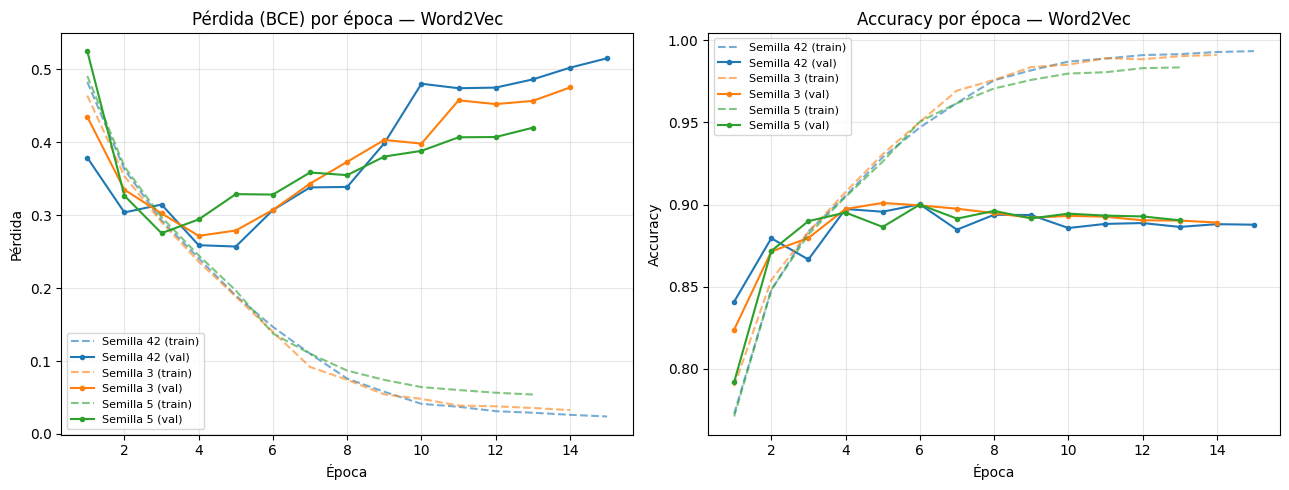

Mejor val_acc por semilla:
  Semilla 42: 0.9001
  Semilla 3: 0.9010
  Semilla 5: 0.9000


In [72]:
# ===== 13. Resultados: gráficas de pérdida y accuracy (3 semillas) =====
corridas = {
    "Semilla 42": historial,
    "Semilla 3":  historial_s3,
    "Semilla 5":  historial_s5,
}
colores = {"Semilla 42": "tab:blue", "Semilla 3": "tab:orange", "Semilla 5": "tab:green"}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for nombre, h in corridas.items():
    epocas_x = range(1, len(h["train_loss"]) + 1)
    c = colores[nombre]
    # Pérdida
    axes[0].plot(epocas_x, h["train_loss"], color=c, linestyle="--", alpha=0.6,
                 label=f"{nombre} (train)")
    axes[0].plot(epocas_x, h["val_loss"],  color=c, linestyle="-",  marker="o", markersize=3,
                 label=f"{nombre} (val)")
    # Accuracy
    axes[1].plot(epocas_x, h["train_acc"], color=c, linestyle="--", alpha=0.6,
                 label=f"{nombre} (train)")
    axes[1].plot(epocas_x, h["val_acc"],   color=c, linestyle="-",  marker="o", markersize=3,
                 label=f"{nombre} (val)")

axes[0].set_title("Pérdida (BCE) por época — Word2Vec")
axes[0].set_xlabel("Época"); axes[0].set_ylabel("Pérdida")

axes[1].set_title("Accuracy por época — Word2Vec")
axes[1].set_xlabel("Época"); axes[1].set_ylabel("Accuracy")

for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

# Resumen del mejor val_acc de cada semilla
print("Mejor val_acc por semilla:")
for nombre, h in corridas.items():
    print(f"  {nombre}: {max(h['val_acc']):.4f}")


### 14. Evaluación en el conjunto de prueba

Se evalúa una sola vez el mejor modelo (según validación) con el 30 % de prueba, que no se usó para entrenar ni para elegir el modelo. Se reportan precisión, recall y F1-score por clase, junto con la matriz de confusión.

Accuracy : 0.8944
Precisión: 0.9026
Recall   : 0.8848
F1-score : 0.8936

              precision    recall  f1-score   support

    Negativa     0.8865    0.9041    0.8953      2973
    Positiva     0.9026    0.8848    0.8936      2986

    accuracy                         0.8944      5959
   macro avg     0.8946    0.8945    0.8944      5959
weighted avg     0.8946    0.8944    0.8944      5959



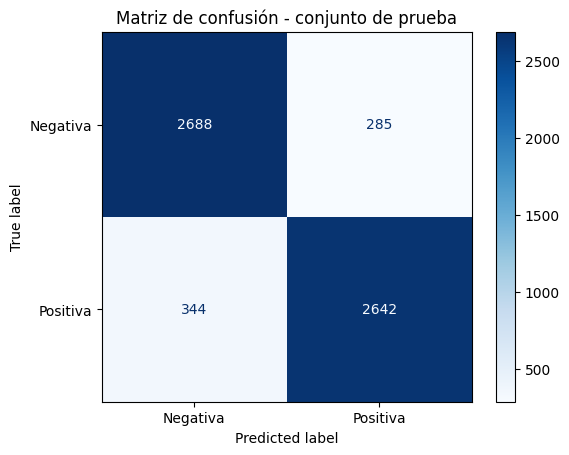

In [73]:
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score)

modelo.eval()
probs, reales = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        probs.append(modelo(xb.to(device)).cpu())
        reales.append(yb)
probs = torch.cat(probs).numpy()
y_real = torch.cat(reales).numpy().astype(int)
y_pred = (probs >= 0.5).astype(int)

print(f"Accuracy : {accuracy_score(y_real, y_pred):.4f}")
print(f"Precisión: {precision_score(y_real, y_pred):.4f}")
print(f"Recall   : {recall_score(y_real, y_pred):.4f}")
print(f"F1-score : {f1_score(y_real, y_pred):.4f}\n")
print(classification_report(y_real, y_pred, target_names=["Negativa", "Positiva"], digits=4))

ConfusionMatrixDisplay(confusion_matrix(y_real, y_pred),
                       display_labels=["Negativa", "Positiva"]).plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión - conjunto de prueba")
plt.show()